# Exploring STAT1 and interferon-response markers with TERRA

This notebook explores two questions in one public Xenium melanoma tissue section:

1. Is observed STAT1 expression associated with a small interferon-response marker score?
2. Is that observed score associated with how much TERRA's embedding changes when the STAT1 input token is removed?

The second question concerns **model sensitivity**. Removing an input token is not an experimental knockout, and an embedding shift is not a predicted change in phenotype or gene expression. See the accompanying README for results, provenance, limitations, and a CPU-only check of the saved tables.

The outputs shown below come from the supplied Colab run on a T4 GPU. Some long installation, table-widget and repeated error logs were removed from this copy for readability; figures and analysis results are retained. The original run emitted ignored `BytesIO` `BufferError` traces and dependency warnings, and their cause is unresolved. This cleaned copy has not been independently rerun end to end.

## 1. Set up the Colab runtime

Use a GPU runtime for TERRA and run the cells in order. The package version is pinned below; other transitive dependencies may vary over time.


In [3]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [ ]:
%pip install "terra-st==0.1.13"

In [5]:
import torch
import terra

print("TERRA version:", terra.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


TERRA version: 0.1.13
PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


## 2. Download the public tissue data

This cell downloads the full 10x Genomics Xenium melanoma input, which is not included in the repository. It may take substantial disk space and time. The next cells inspect gene identifiers and candidates before selecting a spatial region.


In [6]:
from terra.datasets import read_xenium_10x

dataset_url = (
    "https://cf.10xgenomics.com/samples/xenium/3.0.0/"
    "Xenium_Prime_Human_Skin_FFPE/"
    "Xenium_Prime_Human_Skin_FFPE"
)

adata_full = read_xenium_10x(
    base_url=dataset_url,
    out_dir="data/xenium_skin"
)

print(adata_full)

AnnData object with n_obs × n_vars = 112551 × 5006
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'
    layers: None (.X)


In [11]:
import numpy as np
import pandas as pd
from google.colab import data_table

gene_table = adata_full.var.copy().reset_index(drop=True)

gene_table.insert(
    0,
    "feature_name",
    adata_full.var_names.astype(str).to_numpy()
)

gene_table["cells_detected"] = np.asarray(
    (adata_full.X > 0).sum(axis=0)
).ravel().astype(int)


gene_table["percent_detected"] = (
    100 * gene_table["cells_detected"] / adata_full.n_obs
).round(2)


gene_table = gene_table.sort_values("feature_name").reset_index(drop=True)

print("Number of genes:", len(gene_table))

display(
    data_table.DataTable(
        gene_table,
        include_index=False,
        num_rows_per_page=20
    )
)

Number of genes: 5006


In [12]:
candidates = {
    "B2M": "ENSG00000166710",
    "CD274": "ENSG00000120217",
    "JAK1": "ENSG00000162434",
    "STAT1": "ENSG00000115415",
    "BRAF": "ENSG00000157764"
}

# Prepare the two columns for the gene search.
feature_names = (
    gene_table["feature_name"]
    .astype(str)
    .str.upper()
    .str.replace(r"\.\d+$", "", regex=True)
)

gene_ids = (
    gene_table["gene_ids"]
    .astype(str)
    .str.upper()
    .str.replace(r"\.\d+$", "", regex=True)
)

for symbol, ensembl_id in candidates.items():

    matches = gene_table[
        feature_names.isin([symbol, ensembl_id]) |
        gene_ids.isin([symbol, ensembl_id])
    ]

    print(f"\n--- {symbol} ---")

    if matches.empty:
        print("Not found in the two checked columns.")
    else:
        display(
            matches[
                [
                    "feature_name",
                    "gene_ids",
                    "cells_detected",
                    "percent_detected"
                ]
            ]
        )


--- B2M ---
Not found in the two checked columns.

--- CD274 ---


,feature_name,gene_ids,cells_detected,percent_detected
668,CD274,ENSG00000120217,2959,2.63



--- JAK1 ---


,feature_name,gene_ids,cells_detected,percent_detected
2266,JAK1,ENSG00000162434,6838,6.08



--- STAT1 ---


,feature_name,gene_ids,cells_detected,percent_detected
4281,STAT1,ENSG00000115415,51298,45.58



--- BRAF ---


,feature_name,gene_ids,cells_detected,percent_detected
435,BRAF,ENSG00000157764,12017,10.68


## 3. Select the analysis region and its spatial context

Take a central region together with an outer buffer. The initial selection contains 1,885 central cells and 8,180 cells in the larger region. The k-nearest-neighbor check inspects whether central cells have surrounding context inside the crop.


In [13]:
import numpy as np

coordinates = np.asarray(adata_full.obsm["spatial"])

valid_coords = np.isfinite(coordinates).all(axis=1)

center = np.median(coordinates[valid_coords], axis=0)

outer_half_window = 500
core_half_window = 250

outer_mask = valid_coords & (
    np.abs(coordinates - center) <= outer_half_window
).all(axis=1)

adata_region = adata_full[outer_mask].copy()

region_coordinates = np.asarray(adata_region.obsm["spatial"])

core_mask = (
    np.abs(region_coordinates - center) <= core_half_window
).all(axis=1)

adata_region.obs["is_core"] = core_mask
adata_region.obs["cell_id"] = adata_region.obs_names.astype(str)
adata_region.obs["sample"] = "skin_melanoma"

n_core_cells = int(core_mask.sum())

n_stat1_core = int(
    (adata_region[core_mask, "STAT1"].X > 0).sum()
)

print("Cells in the full tissue:", adata_full.n_obs)
print("Cells in the larger region:", adata_region.n_obs)
print("Cells in the central region:", n_core_cells)
print("Central cells with detected STAT1:", n_stat1_core)
print("Cell IDs are unique:", adata_region.obs_names.is_unique)

Cells in the full tissue: 112551
Cells in the larger region: 8180
Cells in the central region: 1885
Central cells with detected STAT1: 956
Cell IDs are unique: True


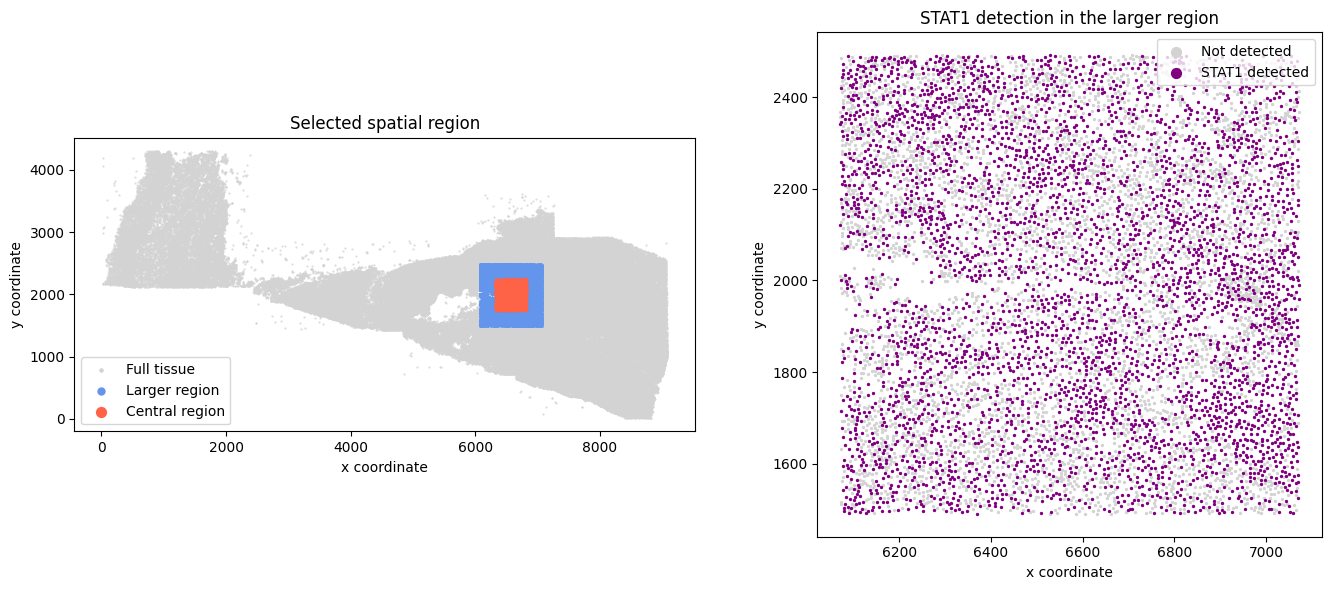

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Coordinates of the full tissue and selected region.
full_xy = np.asarray(adata_full.obsm["spatial"])
region_xy = np.asarray(adata_region.obsm["spatial"])

# Identify the central cells.
core = adata_region.obs["is_core"].to_numpy(dtype=bool)

# Check STAT1 detection in each cell.
stat1_detected = np.asarray(
    (adata_region[:, "STAT1"].X > 0).sum(axis=1)
).ravel() > 0

# Keep this information for later steps.
adata_region.obs["stat1_detected"] = stat1_detected

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# First plot: location of the selected region.
axes[0].scatter(
    full_xy[:, 0], full_xy[:, 1],
    s=0.2, color="lightgray", label="Full tissue"
)

axes[0].scatter(
    region_xy[:, 0], region_xy[:, 1],
    s=1, color="cornflowerblue", label="Larger region"
)

axes[0].scatter(
    region_xy[core, 0], region_xy[core, 1],
    s=2, color="tomato", label="Central region"
)

axes[0].set_title("Selected spatial region")
axes[0].legend(markerscale=5)

# Second plot: STAT1 detection.
axes[1].scatter(
    region_xy[~stat1_detected, 0],
    region_xy[~stat1_detected, 1],
    s=2, color="lightgray", label="Not detected"
)

axes[1].scatter(
    region_xy[stat1_detected, 0],
    region_xy[stat1_detected, 1],
    s=2, color="purple", label="STAT1 detected"
)

axes[1].set_title("STAT1 detection in the larger region")
axes[1].legend(markerscale=5)

for ax in axes:
    ax.set_xlabel("x coordinate")
    ax.set_ylabel("y coordinate")
    ax.set_aspect("equal")

plt.tight_layout()
fig.savefig("spatial_overview.png", dpi=180, bbox_inches="tight")
plt.show()

In [15]:
from sklearn.neighbors import NearestNeighbors

valid = np.isfinite(full_xy).all(axis=1)
valid_rows = np.flatnonzero(valid)

neighbors = NearestNeighbors(n_neighbors=11)
neighbors.fit(full_xy[valid])

neighbor_rows_in_valid = neighbors.kneighbors(
    region_xy[core],
    return_distance=False
)


neighbor_rows_in_full = valid_rows[neighbor_rows_in_valid]


is_in_region = np.asarray(
    adata_full.obs_names.isin(adata_region.obs_names)
)

context_ok = is_in_region[neighbor_rows_in_full].all(axis=1)


adata_region.obs["core_context_ok"] = False
adata_region.obs.loc[
    adata_region.obs["is_core"],
    "core_context_ok"
] = context_ok

print("Central cells checked:", len(context_ok))
print("Cells with all nearby cells inside the crop:", int(context_ok.sum()))
print("Cells needing more context:", int((~context_ok).sum()))

Central cells checked: 1885
Cells with all nearby cells inside the crop: 1885
Cells needing more context: 0


## 4. Load TERRA and harmonize genes

The checkpoint is pinned to a specific revision and is downloaded separately. Harmonization retains 8,163 cells and 3,927 genes in the larger region; STAT1 remains available. Data and model licenses are linked in the README.


In [16]:
from terra import download_pretrained

model_dir = download_pretrained(
    "lotfollahi-lab/TERRA-96M",
    revision="f3a0ea8b0827fc9d49bea5de27e80f0cbf0214bc"
)

print("Model downloaded to:", model_dir)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Model downloaded to: /root/.cache/huggingface/hub/models--lotfollahi-lab--TERRA-96M/snapshots/f3a0ea8b0827fc9d49bea5de27e80f0cbf0214bc


In [17]:
import os
from terra import harmonize_adata

adata_terra = harmonize_adata(
    adata=adata_region.copy(),

    gene_mapping_dict_file_path=os.path.join(
        model_dir, "ensembl_dictionary.pkl"
    ),

    gene_occurrence_count_file_path=os.path.join(
        model_dir, "gene_count_dictionary.pkl"
    ),

    species="human",
    min_genes_per_cell=10,
    min_cells_per_gene=10
)

print("Cells before harmonization:", adata_region.n_obs)
print("Cells after harmonization:", adata_terra.n_obs)

print("Genes before harmonization:", adata_region.n_vars)
print("Genes after harmonization:", adata_terra.n_vars)

stat1_id = "ENSG00000115415"

stat1_retained = (
    adata_terra.var["ensembl_id"]
    .astype(str)
    .str.startswith(stat1_id)
    .any()
)

print("STAT1 retained:", stat1_retained)

Cells before harmonization: 8180
Cells after harmonization: 8163
Genes before harmonization: 5006
Genes after harmonization: 3927
STAT1 retained: True


## 5. Tokenize and check the spatial context after filtering

Tokenization processes the larger region. The follow-up geometry check and ID checks help identify missing context or misaligned cells. They do not validate biological predictions.


In [18]:
from terra import tokenize_adata

tokenized = tokenize_adata(
    adata=adata_terra,
    model_folder_path=model_dir,
    cache_directory_path="./terra_cache",
    nproc=1,
    processing_mode="sequential"
)

print("Number of tokenized cells:", len(tokenized))
print("Tokenized columns:", tokenized.column_names)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/usr/local/lib/python3.13/dist-packages/terra/preprocessors/graph.py:26: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata,


Generating train split: 0 examples [00:00, ? examples/s]

Map (num_proc=1):   0%|          | 0/8163 [00:00<?, ? examples/s]

Number of tokenized cells: 8163
Tokenized columns: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens']


In [19]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

xy_qc = np.asarray(adata_terra.obsm["spatial"])

core_qc = adata_terra.obs["is_core"].to_numpy(dtype=bool)


knn = NearestNeighbors(n_neighbors=11)
knn.fit(xy_qc)

distances, _ = knn.kneighbors(xy_qc[core_qc])


distance_to_edge = outer_half_window - np.max(
    np.abs(xy_qc[core_qc] - center),
    axis=1
)


context_ok = distances[:, -1] < distance_to_edge


adata_terra.obs["context_after_qc"] = False
adata_terra.obs.loc[
    core_qc,
    "context_after_qc"
] = context_ok

print("Central cells after QC:", len(context_ok))
print("Cells with sufficient spatial context:", int(context_ok.sum()))
print("Cells needing a larger crop:", int((~context_ok).sum()))

Central cells after QC: 1881
Cells with sufficient spatial context: 1881
Cells needing a larger crop: 0


## 6. Pilot on five cells

Check the input token, cell IDs, embedding shape and finite values. Then remove the STAT1 token from the central-cell input and compare repeated baseline and edited embeddings. The pilot checks that other central gene content and neighbor segments are retained.


In [20]:
import os
import pickle
import yaml


with open(os.path.join(model_dir, "model_config.yaml")) as file:
    model_config = yaml.safe_load(file)

seq_len_cell = model_config["data"]["seq_len_cell"]


with open(os.path.join(model_dir, "token_dictionary.pkl"), "rb") as file:
    token_dictionary = pickle.load(file)

stat1_token = token_dictionary.get("ENSG00000115415")

if stat1_token is None:
    raise ValueError("STAT1 was not found in the model token dictionary.")


tokenized_plain = tokenized.with_format(None)
tokenized_ids = [str(cell_id) for cell_id in tokenized_plain["cell_id"]]

adata_ids = set(adata_terra.obs_names.astype(str))

print("Tokenized cell IDs are unique:",
      len(tokenized_ids) == len(set(tokenized_ids)))

print("Tokenized IDs match AnnData IDs:",
      set(tokenized_ids) == adata_ids)

eligible = (
    adata_terra.obs["is_core"] &
    adata_terra.obs["context_after_qc"] &
    adata_terra.obs["stat1_detected"]
)

eligible_ids = set(adata_terra.obs_names[eligible].astype(str))

candidate_positions = [
    i for i, cell_id in enumerate(tokenized_ids)
    if cell_id in eligible_ids
]


rng = np.random.default_rng(42)
shuffled_positions = rng.permutation(candidate_positions)

pilot_positions = []

for position in shuffled_positions:
    row = tokenized_plain[int(position)]

    cell_gene_tokens = row["gene_tokens"][:seq_len_cell]

    if stat1_token in cell_gene_tokens:
        pilot_positions.append(int(position))

    if len(pilot_positions) == 5:
        break

if len(pilot_positions) == 0:
    raise ValueError("No suitable cells with the STAT1 token were found.")

pilot_dataset = tokenized.select(pilot_positions)

print("STAT1 token ID:", stat1_token)
print("Pilot cells selected:", len(pilot_dataset))

Tokenized cell IDs are unique: True
Tokenized IDs match AnnData IDs: True
STAT1 token ID: 4490
Pilot cells selected: 5


In [21]:
from terra import embed_dataset

pilot_dataset.set_format(
    type="torch",
    columns=[
        "rel_x_coord",
        "rel_y_coord",
        "cell_id",
        "gene_tokens",
        "gene_expr",
        "n_nonzero_tokens"
    ]
)

pilot_embeddings = embed_dataset(
    dataset=pilot_dataset,
    model_folder_path=model_dir,
    batch_size=1,
    num_workers=0,
    include_spatial_cell_emb=True,
    return_token_embeddings=False
)

for name, values in pilot_embeddings.items():
    values = np.asarray(values)

    print(
        name,
        "| shape:", values.shape,
        "| all finite:", np.isfinite(values).all()
    )

Exception ignored in: <_io.BytesIO object at 0x79dcccb9fa10>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 520, in __init__
    super().__setattr__("_load_state_dict_pre_hooks", OrderedDict())
BufferError: Existing exports of data: object cannot be re-sized
0it [00:00, ?it/s]/usr/local/lib/python3.13/dist-packages/terra/inference/embed.py:265: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
5it [00:03,  1.49it/s]

cell_emb | shape: (5, 384) | all finite: True
neighborhood_emb | shape: (5, 384) | all finite: True
spatial_cell_emb | shape: (5, 384) | all finite: True


In [22]:
import numpy as np
import pandas as pd
from terra import perturb_dataset

stat1_ensembl = "ENSG00000115415"

perturb_df = pd.DataFrame([{
    "perturbed_cell_id": "all",
    "perturbed_ensembl_id": stat1_ensembl,
    "perturbation_target": "cell",
    "perturbation_type": "knockout",
    "foldchange": np.nan,
}])

perturbed_pilot = perturb_dataset(
    dataset=pilot_dataset,
    perturb_df=perturb_df,
    model_folder_path=model_dir,
    seq_len_cell=int(seq_len_cell),
    nproc=1,
    pad_gene_tokens=True,
    adjust_positions=True,
    return_only_perturbed_cells=False,
)

before = pilot_dataset.with_format(None)
after = perturbed_pilot.with_format(None)

before_ids = list(before["cell_id"])
after_ids = list(after["cell_id"])

assert before_ids == after_ids, "Cell IDs or their order do not match."


def same_nonpadding_content(tokens_a, expr_a, tokens_b, expr_b):
    """Compare gene tokens and expression after removing padding."""
    mask_a = tokens_a != 0
    mask_b = tokens_b != 0

    return (
        np.array_equal(tokens_a[mask_a], tokens_b[mask_b])
        and np.allclose(
            expr_a[mask_a],
            expr_b[mask_b],
            equal_nan=True,
        )
    )


checks = []
segment_length = int(seq_len_cell)

for i, cell_id in enumerate(before_ids):
    row_before = before[i]
    row_after = after[i]

    tokens_before = np.asarray(row_before["gene_tokens"])
    tokens_after = np.asarray(row_after["gene_tokens"])
    expr_before = np.asarray(row_before["gene_expr"])
    expr_after = np.asarray(row_after["gene_expr"])

    # First segment: central cell
    central_before = tokens_before[:segment_length]
    central_after = tokens_after[:segment_length]

    stat1_before = int(np.sum(central_before == stat1_token))
    stat1_after = int(np.sum(central_after == stat1_token))

    # Compare the remaining central-cell genes
    keep_before = (
        (central_before != 0)
        & (central_before != stat1_token)
    )
    keep_after = central_after != 0

    other_central_genes_same = (
        np.array_equal(
            central_before[keep_before],
            central_after[keep_after],
        )
        and np.allclose(
            expr_before[:segment_length][keep_before],
            expr_after[:segment_length][keep_after],
            equal_nan=True,
        )
    )

    # Compare each neighboring cell's gene content
    neighbors_same = True

    for start in range(segment_length, len(tokens_before), segment_length):
        stop = start + segment_length

        if not same_nonpadding_content(
            tokens_before[start:stop],
            expr_before[start:stop],
            tokens_after[start:stop],
            expr_after[start:stop],
        ):
            neighbors_same = False
            break

    checks.append({
        "cell_id": cell_id,
        "STAT1_before": stat1_before,
        "STAT1_after": stat1_after,
        "other_central_genes_same": other_central_genes_same,
        "neighbors_same": neighbors_same,
    })

pilot_checks = pd.DataFrame(checks)
display(pilot_checks)

assert (pilot_checks["STAT1_before"] > 0).all()
assert (pilot_checks["STAT1_after"] == 0).all()
assert pilot_checks["other_central_genes_same"].all()
assert pilot_checks["neighbors_same"].all()

print("Pilot perturbation checks passed.")

Map (num_proc=1):   0%|          | 0/5 [00:00<?, ? examples/s]

,cell_id,STAT1_before,STAT1_after,other_central_genes_same,neighbors_same
0,cbmmogmj-1,1,0,True,True
1,iclhgcim-1,1,0,True,True
2,gbdjmmdb-1,1,0,True,True
3,hfbbcflj-1,1,0,True,True
4,fneldiji-1,1,0,True,True


Pilot perturbation checks passed.


In [23]:
from terra import embed_dataset

torch_columns = [
    "rel_x_coord",
    "rel_y_coord",
    "cell_id",
    "gene_tokens",
    "gene_expr",
    "n_nonzero_tokens",
]

pilot_dataset.set_format(type="torch", columns=torch_columns)
perturbed_pilot.set_format(type="torch", columns=torch_columns)

embed_options = dict(
    model_folder_path=model_dir,
    batch_size=1,
    num_workers=0,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    agg_excluded_genes=[stat1_ensembl],
)

print("1/3: baseline")
base = embed_dataset(dataset=pilot_dataset, **embed_options)

print("2/3: baseline repeat")
base_repeat = embed_dataset(dataset=pilot_dataset, **embed_options)

print("3/3: STAT1 knockout")
knockout = embed_dataset(dataset=perturbed_pilot, **embed_options)

base_spatial = np.asarray(base["spatial_cell_emb"])
repeat_spatial = np.asarray(base_repeat["spatial_cell_emb"])
ko_spatial = np.asarray(knockout["spatial_cell_emb"])

assert base_spatial.shape == repeat_spatial.shape == ko_spatial.shape
assert np.isfinite(base_spatial).all()
assert np.isfinite(repeat_spatial).all()
assert np.isfinite(ko_spatial).all()

pilot_results = pd.DataFrame({
    "cell_id": before_ids,
    "no_edit_shift": np.linalg.norm(
        repeat_spatial - base_spatial, axis=1
    ),
    "STAT1_KO_shift": np.linalg.norm(
        ko_spatial - base_spatial, axis=1
    ),
})

display(pilot_results)

1/3: baseline


Exception ignored in: <_io.BytesIO object at 0x79dcaf0499e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1981, in __setattr__
    params = self.__dict__.get("_parameters")
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dcacdc1080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1981, in __setattr__
    params = self.__dict__.get("_parameters")
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dcacdc13f0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1981, in __setattr__
    params = self.__dict__.get("_parameters")
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dcaf04b790>
Traceback

2/3: baseline repeat


5it [00:01,  2.62it/s]


3/3: STAT1 knockout


5it [00:01,  2.61it/s]


,cell_id,no_edit_shift,STAT1_KO_shift
0,cbmmogmj-1,0.0,0.099838
1,iclhgcim-1,0.0,0.100316
2,gbdjmmdb-1,0.0,0.062003
3,hfbbcflj-1,0.0,0.055307
4,fneldiji-1,0.0,0.062680


## 7. STAT1 token removal in 100 cells

Select central cells with detected STAT1 and the STAT1 token present, using random seed 42. Compare each original embedding to its edited version with an L2 distance. Permutation checks test whether returned embeddings follow input order. The distance measures a change in model representation, with no direct biological units.


In [24]:
import numpy as np
import pandas as pd

target_n = 100
segment_length = int(seq_len_cell)

# Select central cells with sufficient context and detected STAT1
eligible_mask = (
    adata_terra.obs["is_core"].astype(bool)
    & adata_terra.obs["context_after_qc"].astype(bool)
    & adata_terra.obs["stat1_detected"].astype(bool)
)

eligible_ids = set(
    adata_terra.obs_names[eligible_mask.to_numpy()].astype(str)
)

tokenized_plain = tokenized.with_format(None)
all_tokenized_ids = list(tokenized_plain["cell_id"])

candidate_positions = [
    i for i, cell_id in enumerate(all_tokenized_ids)
    if str(cell_id) in eligible_ids
]

rng = np.random.default_rng(42)
rng.shuffle(candidate_positions)

selected_positions = []

for position in candidate_positions:
    central_tokens = np.asarray(
        tokenized_plain[position]["gene_tokens"][:segment_length]
    )

    if stat1_token in central_tokens:
        selected_positions.append(position)

    if len(selected_positions) == target_n:
        break

if len(selected_positions) < target_n:
    raise ValueError(
        f"Only {len(selected_positions)} eligible cells found; "
        f"{target_n} were requested."
    )

control_100 = tokenized.select(selected_positions)
control_100.set_format(type="torch", columns=torch_columns)

ids_100 = list(control_100.with_format(None)["cell_id"])

assert len(ids_100) == target_n
assert len(set(ids_100)) == target_n

print("Selected cells:", len(ids_100))
print("Unique cell IDs:", len(set(ids_100)) == target_n)

Selected cells: 100
Unique cell IDs: True


In [25]:
perturbed_100 = perturb_dataset(
    dataset=control_100,
    perturb_df=perturb_df,
    model_folder_path=model_dir,
    seq_len_cell=segment_length,
    nproc=1,
    pad_gene_tokens=True,
    adjust_positions=True,
    return_only_perturbed_cells=False,
)

control_plain = control_100.with_format(None)
ko_plain = perturbed_100.with_format(None)

assert list(control_plain["cell_id"]) == list(ko_plain["cell_id"])

for i in range(target_n):
    tokens_before = np.asarray(control_plain[i]["gene_tokens"])
    tokens_after = np.asarray(ko_plain[i]["gene_tokens"])

    # STAT1 must be present before and absent after knockout
    assert stat1_token in tokens_before[:segment_length]
    assert stat1_token not in tokens_after[:segment_length]

perturbed_100.set_format(type="torch", columns=torch_columns)

print("Cells checked:", target_n)
print("STAT1 was removed from all selected central cells.")
print("Cell IDs and their order match.")

Map (num_proc=1):   0%|          | 0/100 [00:00<?, ? examples/s]

Cells checked: 100
STAT1 was removed from all selected central cells.
Cell IDs and their order match.


Exception ignored in: <_io.BytesIO object at 0x79dcaf048fe0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/lib/py311_tokenize.py", line 532, in _tokenize
    pseudomatch = _compile(PseudoToken).match(line, pos)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dcacdc3330>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/lib/py311_tokenize.py", line 532, in _tokenize
    pseudomatch = _compile(PseudoToken).match(line, pos)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dcacdc18f0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/lib/py311_tokenize.py", line 532, in _tokenize
    pseudomatch = _compile(PseudoToken).match(line, pos)
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO ob

1/4: baseline embeddings


0it [00:00, ?it/s]/usr/local/lib/python3.13/dist-packages/terra/inference/embed.py:265: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
100it [00:40,  2.48it/s]


2/4: STAT1 knockout embeddings


100it [00:40,  2.46it/s]


3/4: checking baseline order


... (2 outputs left out)

100it [00:40,  2.47it/s]

Embedding order checks passed.


,cell_id,x,y,STAT1_KO_shift
0,cbmmogmj-1,6774.866211,1943.773926,0.099838
1,iclhgcim-1,6384.989746,2012.470337,0.100316
2,gbdjmmdb-1,6808.822754,2137.045654,0.062003
3,hfbbcflj-1,6736.041504,2070.112061,0.055307
4,fneldiji-1,6553.139648,1763.254517,0.062680


count    100.000000
mean       0.083756
std        0.051969
min        0.027556
25%        0.055800
50%        0.072078
75%        0.096397
max        0.332857
Name: STAT1_KO_shift, dtype: float64

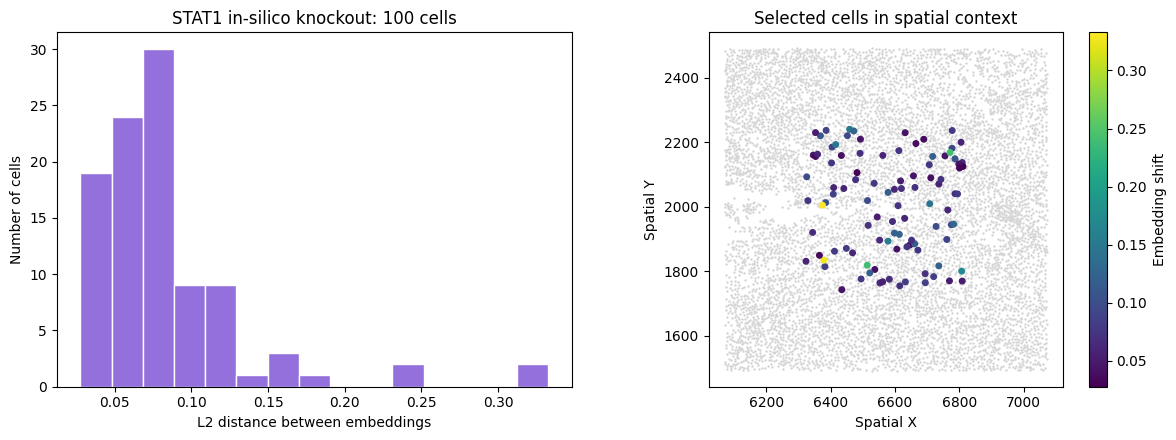

Saved: results/stat1_100_cells.csv
Saved: results/stat1_100_cells.png


In [26]:
import os
import matplotlib.pyplot as plt

def get_spatial_embedding(dataset):
    output = embed_dataset(dataset=dataset, **embed_options)
    embedding = np.asarray(output["spatial_cell_emb"])

    assert embedding.shape[0] == target_n
    assert np.isfinite(embedding).all()

    return embedding


print("1/4: baseline embeddings")
base_100 = get_spatial_embedding(control_100)

print("2/4: STAT1 knockout embeddings")
ko_100 = get_spatial_embedding(perturbed_100)

# Test whether output rows follow the input order
permutation = np.random.default_rng(123).permutation(target_n).tolist()

print("3/4: checking baseline order")
base_shuffled = get_spatial_embedding(
    control_100.select(permutation)
)

print("4/4: checking knockout order")
ko_shuffled = get_spatial_embedding(
    perturbed_100.select(permutation)
)

np.testing.assert_allclose(
    base_shuffled,
    base_100[permutation],
    rtol=1e-4,
    atol=1e-5,
)

np.testing.assert_allclose(
    ko_shuffled,
    ko_100[permutation],
    rtol=1e-4,
    atol=1e-5,
)

print("Embedding order checks passed.")

# Euclidean distance between paired embeddings
shift_100 = np.linalg.norm(ko_100 - base_100, axis=1)

# Match each selected cell with its original spatial coordinates
adata_positions = adata_terra.obs_names.get_indexer(ids_100)
assert (adata_positions >= 0).all()

coords_100 = np.asarray(adata_terra.obsm["spatial"])[adata_positions]

results_100 = pd.DataFrame({
    "cell_id": ids_100,
    "x": coords_100[:, 0],
    "y": coords_100[:, 1],
    "STAT1_KO_shift": shift_100,
})

display(results_100.head())
display(results_100["STAT1_KO_shift"].describe())

# Save a small table
os.makedirs("results", exist_ok=True)
results_100.to_csv("results/stat1_100_cells.csv", index=False)

# Plot the distribution and the selected cells' locations
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(shift_100, bins=15, color="mediumpurple", edgecolor="white")
axes[0].set_xlabel("L2 distance between embeddings")
axes[0].set_ylabel("Number of cells")
axes[0].set_title("STAT1 in-silico knockout: 100 cells")

region_coords = np.asarray(adata_terra.obsm["spatial"])

axes[1].scatter(
    region_coords[:, 0],
    region_coords[:, 1],
    s=0.5,
    color="lightgray",
    label="Region cells",
)

points = axes[1].scatter(
    coords_100[:, 0],
    coords_100[:, 1],
    c=shift_100,
    cmap="viridis",
    s=16,
)

axes[1].set_xlabel("Spatial X")
axes[1].set_ylabel("Spatial Y")
axes[1].set_title("Selected cells in spatial context")
axes[1].set_aspect("equal")
fig.colorbar(points, ax=axes[1], label="Embedding shift")

plt.tight_layout()
plt.savefig("results/stat1_100_cells.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: results/stat1_100_cells.csv")
print("Saved: results/stat1_100_cells.png")

## 8. Compare against a rank-matched gene

Choose a comparison gene based on token ranks without using the embedding shifts. The saved run selects TDRD3 and finds both tokens in 60 cells. Re-embed the two edits using the same aggregation exclusions; TDRD3 is a comparison gene, not a validated negative control.


In [27]:
import os
import pickle
from collections import defaultdict

import numpy as np
import pandas as pd

# Load the model's Ensembl ID → token dictionary
with open(os.path.join(model_dir, "token_dictionary.pkl"), "rb") as f:
    gene_to_token = pickle.load(f)

assert int(gene_to_token[stat1_ensembl]) == int(stat1_token)

token_to_ensembl = {
    int(token): gene_id
    for gene_id, token in gene_to_token.items()
    if isinstance(gene_id, str) and gene_id.startswith("ENSG")
}

control_plain = control_100.with_format(None)
rank_differences = defaultdict(list)

for i in range(len(control_plain)):
    central_tokens = np.asarray(
        control_plain[i]["gene_tokens"][:segment_length]
    )

    # Position within the central cell's token sequence
    ranks = {}

    for position, token in enumerate(central_tokens, start=1):
        token = int(token)

        if token != 0 and token not in ranks:
            ranks[token] = position

    stat1_rank = ranks[int(stat1_token)]

    for token, rank in ranks.items():
        if token != int(stat1_token) and token in token_to_ensembl:
            rank_differences[token].append(abs(rank - stat1_rank))

candidate_rows = []

for token, differences in rank_differences.items():
    candidate_rows.append({
        "token": token,
        "ensembl_id": token_to_ensembl[token],
        "shared_cells": len(differences),
        "median_abs_rank_difference": np.median(differences),
    })

candidates = pd.DataFrame(
    candidate_rows,
    columns=[
        "token",
        "ensembl_id",
        "shared_cells",
        "median_abs_rank_difference",
    ],
)

candidates = (
    candidates[candidates["shared_cells"] >= 50]
    .sort_values(
        ["median_abs_rank_difference", "shared_cells", "ensembl_id"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)

if candidates.empty:
    raise ValueError("No comparison gene was found in at least 50 cells.")

reference_token = int(candidates.loc[0, "token"])
reference_gene = candidates.loc[0, "ensembl_id"]

print("Selected comparison gene:", reference_gene)
print("Number of shared cells:", int(candidates.loc[0, "shared_cells"]))
print(
    "Median absolute rank difference:",
    candidates.loc[0, "median_abs_rank_difference"],
)

# Show its name in the AnnData metadata if available
if "ensembl_id" in adata_terra.var.columns:
    gene_mask = (
        adata_terra.var["ensembl_id"].astype(str) == reference_gene
    )
    print(
        "Name(s) in AnnData:",
        adata_terra.var_names[gene_mask.to_numpy()].tolist(),
    )

display(candidates.head())

Selected comparison gene: ENSG00000083544
Number of shared cells: 60
Median absolute rank difference: 25.0
Name(s) in AnnData: ['TDRD3']


,token,ensembl_id,shared_cells,median_abs_rank_difference
0,1694,ENSG00000083544,60,25.0
1,7426,ENSG00000137203,62,28.5
2,8193,ENSG00000142168,50,32.0
3,10101,ENSG00000157873,51,35.0
4,9594,ENSG00000153179,68,39.0


In [28]:
# Positions where the comparison gene is present
shared_positions = []

for i in range(len(control_plain)):
    central_tokens = np.asarray(
        control_plain[i]["gene_tokens"][:segment_length]
    )

    if reference_token in central_tokens:
        shared_positions.append(i)

matched_control = control_100.select(shared_positions)
matched_stat1_ko = perturbed_100.select(shared_positions)

reference_perturb_df = pd.DataFrame([{
    "perturbed_cell_id": "all",
    "perturbed_ensembl_id": reference_gene,
    "perturbation_target": "cell",
    "perturbation_type": "knockout",
    "foldchange": np.nan,
}])

matched_reference_ko = perturb_dataset(
    dataset=matched_control,
    perturb_df=reference_perturb_df,
    model_folder_path=model_dir,
    seq_len_cell=segment_length,
    nproc=1,
    pad_gene_tokens=True,
    adjust_positions=True,
    return_only_perturbed_cells=False,
)

matched_base_plain = matched_control.with_format(None)
matched_stat1_plain = matched_stat1_ko.with_format(None)
matched_ref_plain = matched_reference_ko.with_format(None)

matched_ids = list(matched_base_plain["cell_id"])

assert matched_ids == list(matched_stat1_plain["cell_id"])
assert matched_ids == list(matched_ref_plain["cell_id"])

for i in range(len(matched_ids)):
    original = np.asarray(
        matched_base_plain[i]["gene_tokens"][:segment_length]
    )
    stat1_ko = np.asarray(
        matched_stat1_plain[i]["gene_tokens"][:segment_length]
    )
    reference_ko = np.asarray(
        matched_ref_plain[i]["gene_tokens"][:segment_length]
    )

    assert stat1_token in original
    assert reference_token in original

    assert stat1_token not in stat1_ko
    assert reference_token not in reference_ko

    # The other target gene should remain in each edited cell
    assert reference_token in stat1_ko
    assert stat1_token in reference_ko

for dataset in [
    matched_control,
    matched_stat1_ko,
    matched_reference_ko,
]:
    dataset.set_format(type="torch", columns=torch_columns)

print("Matched cells:", len(matched_ids))
print("Cell IDs and targeted gene checks passed.")

Map (num_proc=1):   0%|          | 0/60 [00:00<?, ? examples/s]

Matched cells: 60
Cell IDs and targeted gene checks passed.


Exception ignored in: <_io.BytesIO object at 0x79dcad640130>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/parameter.py", line 21, in __instancecheck__
    def __instancecheck__(self, instance) -> bool:
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dccc148090>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/parameter.py", line 21, in __instancecheck__
    def __instancecheck__(self, instance) -> bool:
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dccc148450>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/parameter.py", line 21, in __instancecheck__
    def __instancecheck__(self, instance) -> bool:
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x79dccc14872

Embedding: baseline


0it [00:00, ?it/s]/usr/local/lib/python3.13/dist-packages/terra/inference/embed.py:265: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
60it [00:24,  2.48it/s]


Checking order: baseline


60it [00:24,  2.42it/s]


Embedding: STAT1_KO


... (7 outputs left out)

Embedding order checks passed.


,cell_id,reference_gene,STAT1_shift,reference_shift,difference
0,cbmmogmj-1,ENSG00000083544,0.099400,0.062816,0.036584
1,iclhgcim-1,ENSG00000083544,0.100108,0.055704,0.044404
2,hfbbcflj-1,ENSG00000083544,0.054518,0.055474,-0.000956
3,fneldiji-1,ENSG00000083544,0.063758,0.058823,0.004935
4,icphifpc-1,ENSG00000083544,0.151395,0.077999,0.073396


,STAT1_shift,reference_shift,difference
count,60.000000,60.000000,60.000000
mean,0.082339,0.071797,0.010542
std,0.048758,0.023561,0.054551
min,0.027642,0.034150,-0.065453
25%,0.058280,0.058043,-0.011012
50%,0.072415,0.067867,0.002102
75%,0.086523,0.083740,0.012533
max,0.326485,0.133175,0.284825


Cells with a larger STAT1 shift: 35 / 60


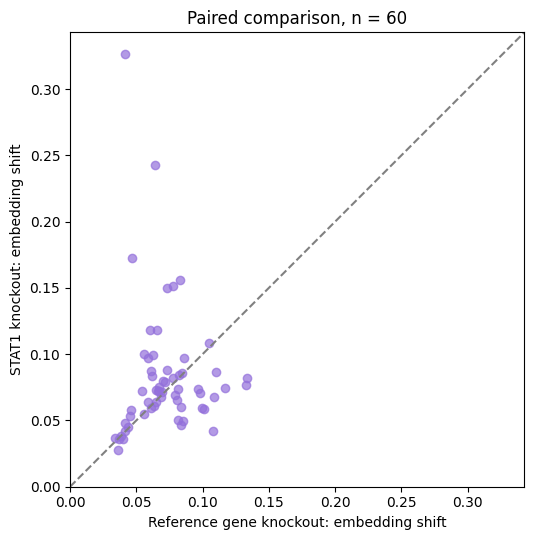

In [29]:
import matplotlib.pyplot as plt

comparison_options = dict(embed_options)
comparison_options["agg_excluded_genes"] = [
    stat1_ensembl,
    reference_gene,
]

datasets_to_embed = {
    "baseline": matched_control,
    "STAT1_KO": matched_stat1_ko,
    "reference_KO": matched_reference_ko,
}

n_matched = len(matched_ids)
permutation = np.random.default_rng(123).permutation(n_matched).tolist()

embeddings = {}

for name, dataset in datasets_to_embed.items():
    print(f"Embedding: {name}")

    original = np.asarray(
        embed_dataset(
            dataset=dataset,
            **comparison_options,
        )["spatial_cell_emb"]
    )

    print(f"Checking order: {name}")

    shuffled = np.asarray(
        embed_dataset(
            dataset=dataset.select(permutation),
            **comparison_options,
        )["spatial_cell_emb"]
    )

    assert original.shape[0] == n_matched
    assert np.isfinite(original).all()

    np.testing.assert_allclose(
        shuffled,
        original[permutation],
        rtol=1e-4,
        atol=1e-5,
    )

    embeddings[name] = original

print("Embedding order checks passed.")

stat1_shift_matched = np.linalg.norm(
    embeddings["STAT1_KO"] - embeddings["baseline"],
    axis=1,
)

reference_shift = np.linalg.norm(
    embeddings["reference_KO"] - embeddings["baseline"],
    axis=1,
)

comparison_results = pd.DataFrame({
    "cell_id": matched_ids,
    "reference_gene": reference_gene,
    "STAT1_shift": stat1_shift_matched,
    "reference_shift": reference_shift,
    "difference": stat1_shift_matched - reference_shift,
})

display(comparison_results.head())
display(
    comparison_results[
        ["STAT1_shift", "reference_shift", "difference"]
    ].describe()
)

print(
    "Cells with a larger STAT1 shift:",
    int((stat1_shift_matched > reference_shift).sum()),
    "/",
    n_matched,
)

# Save the comparison
os.makedirs("results", exist_ok=True)
comparison_results.to_csv(
    "results/stat1_vs_reference.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(5.5, 5.5))

ax.scatter(
    reference_shift,
    stat1_shift_matched,
    alpha=0.7,
    color="mediumpurple",
)

limit = max(reference_shift.max(), stat1_shift_matched.max()) * 1.05
ax.plot([0, limit], [0, limit], "--", color="gray")

ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel("Reference gene knockout: embedding shift")
ax.set_ylabel("STAT1 knockout: embedding shift")
ax.set_title(f"Paired comparison, n = {n_matched}")
ax.set_aspect("equal")

plt.tight_layout()
plt.savefig(
    "results/stat1_vs_reference.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## 9. Calculate an observed interferon-marker score

For the QC-passing central cells, normalize raw marker counts by each cell's total panel counts, apply `log1p`, and average across available markers. Nine of the 12 selected markers match the input feature names. The score excludes STAT1, although its denominator includes total panel counts. This sparse marker average is not the full Hallmark signature or a direct measurement of IFN-gamma activity.

Compare this observed score with observed STAT1 expression and with the already computed embedding shifts. These are descriptive, exploratory associations from a single tissue section.


In [30]:
import os
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# A small, predefined subset of IFN-response genes.
# STAT1 and TDRD3 are deliberately excluded.
ifn_markers = [
    "IRF1",
    "IFIT1",
    "IFIT2",
    "IFIT3",
    "ISG15",
    "MX1",
    "CXCL9",
    "CXCL10",
    "CXCL11",
    "TAP1",
    "PSMB8",
    "PSMB9",
]

# Find which variable field contains gene symbols
possible_names = {
    "var_names": np.asarray(adata_region.var_names.astype(str))
}

for column in [
    "feature_name",
    "gene_name",
    "gene_symbol",
    "gene_symbols",
    "symbol",
]:
    if column in adata_region.var.columns:
        possible_names[column] = (
            adata_region.var[column].astype(str).to_numpy()
        )

name_source, gene_names = max(
    possible_names.items(),
    key=lambda item: (
        int(np.any(item[1] == "STAT1")),
        int(np.isin(item[1], ifn_markers).sum()),
    ),
)

if not np.any(gene_names == "STAT1"):
    raise ValueError(
        "STAT1 was not found as a gene symbol. "
        "Please check adata_region.var and adata_region.var_names."
    )


def unique_gene_position(gene):
    positions = np.flatnonzero(gene_names == gene)

    if len(positions) > 1:
        raise ValueError(f"More than one feature matches {gene}.")

    if len(positions) == 0:
        return None

    return int(positions[0])


stat1_position = unique_gene_position("STAT1")

present_markers = [
    gene for gene in ifn_markers
    if unique_gene_position(gene) is not None
]

missing_markers = [
    gene for gene in ifn_markers
    if gene not in present_markers
]

if len(present_markers) < 5:
    raise ValueError(
        f"Only {len(present_markers)} marker genes are present: "
        f"{present_markers}. Please inspect gene identifiers."
    )

marker_positions = [
    unique_gene_position(gene)
    for gene in present_markers
]

# Use central cells that survived harmonization/QC
core_mask = (
    adata_terra.obs["is_core"].astype(bool)
    & adata_terra.obs["context_after_qc"].astype(bool)
).to_numpy()

core_ids = pd.Index(adata_terra.obs_names[core_mask]).astype(str)
region_ids = pd.Index(adata_region.obs_names).astype(str)

assert core_ids.is_unique
assert region_ids.is_unique

row_positions = region_ids.get_indexer(core_ids)

if (row_positions < 0).any():
    raise ValueError("Some central cell IDs were not found in adata_region.")

# Original raw counts, for the same central cells
raw = adata_region.X[row_positions, :]

if sparse.issparse(raw):
    raw = raw.tocsr()
    raw_values = raw.data
else:
    raw = np.asarray(raw)
    raw_values = raw.ravel()

assert np.isfinite(raw_values).all()
assert (raw_values >= 0).all()
assert np.allclose(raw_values, np.rint(raw_values))

total_counts = np.asarray(raw.sum(axis=1)).ravel()

if (total_counts <= 0).any():
    raise ValueError("At least one cell has zero total counts.")

marker_raw = raw[:, marker_positions]
marker_detection = np.asarray((marker_raw > 0).sum(axis=0)).ravel()
markers_per_cell = np.asarray((marker_raw > 0).sum(axis=1)).ravel()

if np.count_nonzero(marker_detection) < 3:
    raise ValueError(
        "Fewer than three available markers were detected in the core cells."
    )

# Normalize to 10,000 counts per cell, then log1p.
# The score is the mean across the available marker genes.
scale = 10_000 / total_counts

if sparse.issparse(marker_raw):
    marker_log = (
        marker_raw.astype(float)
        .multiply(scale[:, None])
        .tocsr()
    )
    marker_log.data = np.log1p(marker_log.data)
    ifn_score = np.asarray(marker_log.mean(axis=1)).ravel()

    stat1_counts = raw[:, stat1_position].toarray().ravel()
else:
    marker_log = np.log1p(
        np.asarray(marker_raw, dtype=float) * scale[:, None]
    )
    ifn_score = marker_log.mean(axis=1)

    stat1_counts = np.asarray(raw[:, stat1_position]).ravel()

stat1_log = np.log1p(stat1_counts * scale)

coordinates = np.asarray(adata_region.obsm["spatial"])[row_positions]

core_scores = pd.DataFrame({
    "cell_id": core_ids.to_numpy(),
    "x": coordinates[:, 0],
    "y": coordinates[:, 1],
    "total_counts": total_counts,
    "STAT1_counts": stat1_counts,
    "STAT1_log1p_10k": stat1_log,
    "IFN_marker_score": ifn_score,
    "IFN_markers_detected": markers_per_cell,
})

gene_detection = pd.DataFrame({
    "gene": present_markers,
    "cells_detected": marker_detection,
    "percent_detected": 100 * marker_detection / len(core_scores),
}).sort_values("percent_detected", ascending=False)

print("Gene names read from:", name_source)
print("Central cells:", len(core_scores))
print("Markers used:", present_markers)
print("Markers missing:", missing_markers)
print(
    "Cells with IFN score = 0:",
    int((core_scores["IFN_marker_score"] == 0).sum()),
)
print(
    "Median detected markers per cell:",
    core_scores["IFN_markers_detected"].median(),
)

display(gene_detection)
display(core_scores.head())

Gene names read from: var_names
Central cells: 1881
Markers used: ['IRF1', 'IFIT1', 'IFIT2', 'IFIT3', 'MX1', 'CXCL9', 'CXCL10', 'CXCL11', 'TAP1']
Markers missing: ['ISG15', 'PSMB8', 'PSMB9']
Cells with IFN score = 0: 810
Median detected markers per cell: 1.0


,gene,cells_detected,percent_detected
8,TAP1,558,29.665072
4,MX1,284,15.098352
3,IFIT3,235,12.493355
0,IRF1,199,10.579479
5,CXCL9,160,8.506114
6,CXCL10,96,5.103668
1,IFIT1,92,4.891015
2,IFIT2,64,3.402446
7,CXCL11,42,2.232855


,cell_id,x,y,total_counts,STAT1_counts,STAT1_log1p_10k,IFN_marker_score,IFN_markers_detected
0,ajoikdip-1,6747.939941,1976.362793,1666.0,1.0,1.946253,0.285035,1
1,ajoiomci-1,6716.368652,1969.215088,804.0,0.0,0.000000,0.577349,2
2,ajokhbpb-1,6723.541504,1962.372559,545.0,1.0,2.962621,0.447352,1
3,ajokkdnp-1,6740.191895,2024.723145,650.0,1.0,2.796343,0.310705,1
4,ajolailc-1,6750.246094,2007.948242,24.0,0.0,0.000000,0.000000,0


In [31]:
# Join the existing model results to the observed expression scores
model_100 = results_100[
    ["cell_id", "STAT1_KO_shift"]
].copy()

model_60 = comparison_results[
    ["cell_id", "STAT1_shift", "reference_shift", "difference"]
].copy()

model_100["cell_id"] = model_100["cell_id"].astype(str)
model_60["cell_id"] = model_60["cell_id"].astype(str)
core_scores["cell_id"] = core_scores["cell_id"].astype(str)

model_100 = model_100.merge(
    core_scores,
    on="cell_id",
    how="left",
    validate="one_to_one",
)

model_60 = model_60.merge(
    core_scores,
    on="cell_id",
    how="left",
    validate="one_to_one",
)

assert len(model_100) == 100
assert len(model_60) == 60
assert model_100["IFN_marker_score"].notna().all()
assert model_60["IFN_marker_score"].notna().all()
assert set(model_60["cell_id"]).issubset(set(model_100["cell_id"]))

# Obtain STAT1 token rank as a simple technical diagnostic
plain_control = control_100.with_format(None)
stat1_ranks = {}

for i in range(len(plain_control)):
    row = plain_control[i]

    tokens = np.asarray(
        row["gene_tokens"][:int(seq_len_cell)]
    )

    positions = np.flatnonzero(tokens == int(stat1_token))

    assert len(positions) == 1

    # Rank 1 means the first position in the central-cell sequence
    stat1_ranks[str(row["cell_id"])] = int(positions[0] + 1)

model_100["STAT1_token_rank"] = (
    model_100["cell_id"].map(stat1_ranks)
)

assert model_100["STAT1_token_rank"].notna().all()


def safe_spearman(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if (
        len(x) < 3
        or len(np.unique(x)) < 2
        or len(np.unique(y)) < 2
    ):
        return np.nan

    return float(spearmanr(x, y).statistic)


comparisons = [
    (
        "Observed STAT1 expression vs IFN score",
        core_scores,
        "STAT1_log1p_10k",
    ),
    (
        "STAT1 embedding shift vs IFN score",
        model_100,
        "STAT1_KO_shift",
    ),
    (
        "Matched STAT1 shift vs IFN score",
        model_60,
        "STAT1_shift",
    ),
    (
        "Matched TDRD3 shift vs IFN score",
        model_60,
        "reference_shift",
    ),
    (
        "Matched shift difference vs IFN score",
        model_60,
        "difference",
    ),
    (
        "Total counts vs IFN score: technical check",
        model_100,
        "total_counts",
    ),
    (
        "STAT1 token rank vs IFN score: technical check",
        model_100,
        "STAT1_token_rank",
    ),
]

ifn_summary = pd.DataFrame([
    {
        "comparison": label,
        "n_cells": len(data),
        "spearman_rho": safe_spearman(
            data["IFN_marker_score"],
            data[column],
        ),
    }
    for label, data, column in comparisons
])

display(ifn_summary.round(3))

,comparison,n_cells,spearman_rho
0,Observed STAT1 expression vs IFN score,1881,0.178
1,STAT1 embedding shift vs IFN score,100,-0.053
2,Matched STAT1 shift vs IFN score,60,0.163
3,Matched TDRD3 shift vs IFN score,60,0.094
4,Matched shift difference vs IFN score,60,0.087
5,Total counts vs IFN score: technical check,100,-0.136
6,STAT1 token rank vs IFN score: technical check,100,0.026


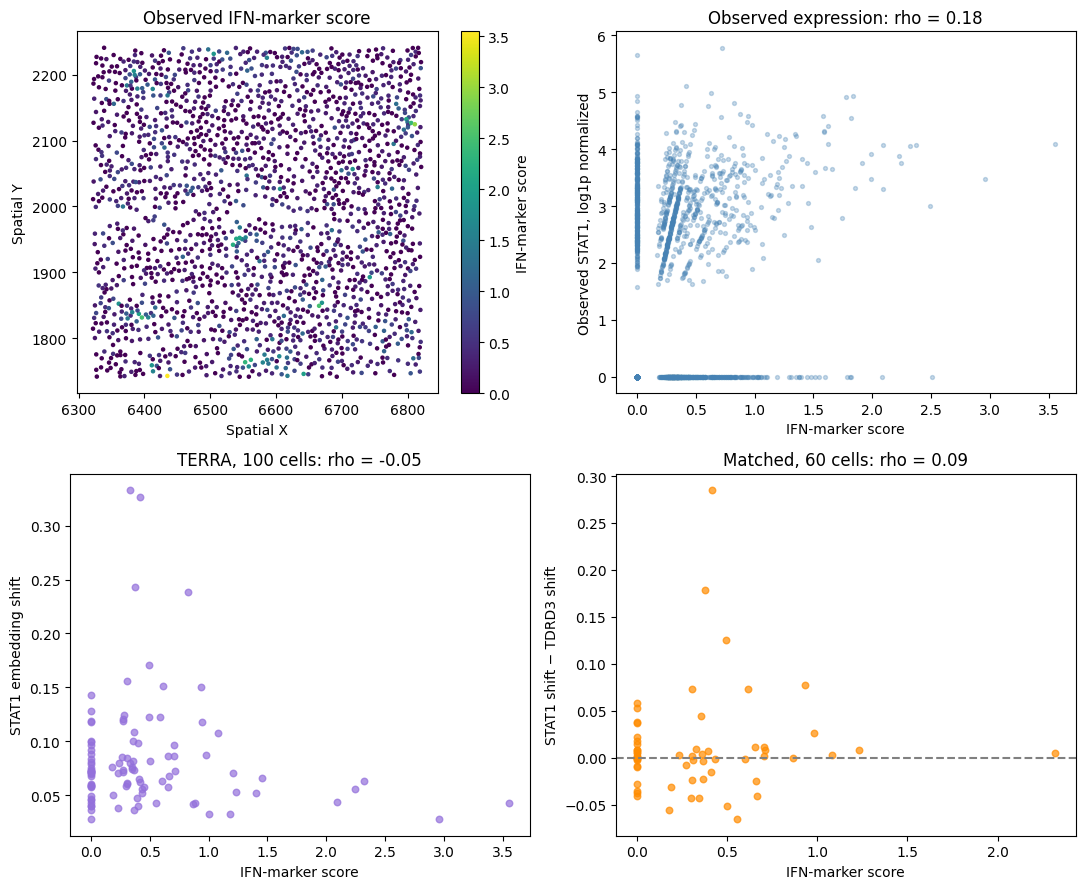

Figure and tables saved in results/


In [32]:
def summary_rho(label):
    value = ifn_summary.loc[
        ifn_summary["comparison"] == label,
        "spearman_rho",
    ].iloc[0]

    return f"{value:.2f}" if np.isfinite(value) else "N/A"


fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# 1. Spatial distribution of the observed marker score
points = axes[0, 0].scatter(
    core_scores["x"],
    core_scores["y"],
    c=core_scores["IFN_marker_score"],
    s=5,
    cmap="viridis",
)

axes[0, 0].set_title("Observed IFN-marker score")
axes[0, 0].set_xlabel("Spatial X")
axes[0, 0].set_ylabel("Spatial Y")
axes[0, 0].set_aspect("equal")
fig.colorbar(points, ax=axes[0, 0], label="IFN-marker score")

# 2. Observed STAT1 expression vs observed IFN markers
rho_observed = summary_rho(
    "Observed STAT1 expression vs IFN score"
)

axes[0, 1].scatter(
    core_scores["IFN_marker_score"],
    core_scores["STAT1_log1p_10k"],
    s=8,
    alpha=0.3,
    color="steelblue",
)

axes[0, 1].set_xlabel("IFN-marker score")
axes[0, 1].set_ylabel("Observed STAT1, log1p normalized")
axes[0, 1].set_title(f"Observed expression: rho = {rho_observed}")

# 3. Baseline IFN markers vs model shift in 100 cells
rho_model = summary_rho(
    "STAT1 embedding shift vs IFN score"
)

axes[1, 0].scatter(
    model_100["IFN_marker_score"],
    model_100["STAT1_KO_shift"],
    s=22,
    alpha=0.7,
    color="mediumpurple",
)

axes[1, 0].set_xlabel("IFN-marker score")
axes[1, 0].set_ylabel("STAT1 embedding shift")
axes[1, 0].set_title(f"TERRA, 100 cells: rho = {rho_model}")

# 4. STAT1 minus TDRD3 shift in matched cells
rho_difference = summary_rho(
    "Matched shift difference vs IFN score"
)

axes[1, 1].scatter(
    model_60["IFN_marker_score"],
    model_60["difference"],
    s=22,
    alpha=0.7,
    color="darkorange",
)

axes[1, 1].axhline(0, linestyle="--", color="gray")
axes[1, 1].set_xlabel("IFN-marker score")
axes[1, 1].set_ylabel("STAT1 shift − TDRD3 shift")
axes[1, 1].set_title(f"Matched, 60 cells: rho = {rho_difference}")

plt.tight_layout()

os.makedirs("results", exist_ok=True)

plt.savefig(
    "results/ifn_context_analysis.png",
    dpi=200,
    bbox_inches="tight",
)

gene_detection.to_csv(
    "results/ifn_gene_detection.csv",
    index=False,
)

core_scores.to_csv(
    "results/ifn_core_scores.csv",
    index=False,
)

model_100.to_csv(
    "results/ifn_stat1_100.csv",
    index=False,
)

model_60.to_csv(
    "results/ifn_stat1_tdrd3_60.csv",
    index=False,
)

ifn_summary.to_csv(
    "results/ifn_analysis_summary.csv",
    index=False,
)

plt.show()
print("Figure and tables saved in results/")

## 10. Check sensitivity to individual markers

Recalculate the marker score after leaving out each available gene in turn. This post-hoc check uses the same data and does not rerun the GPU model; it is not independent biological validation.


In [33]:
marker_array = (
    marker_log.toarray()
    if sparse.issparse(marker_log)
    else np.asarray(marker_log)
)

assert marker_array.shape == (
    len(core_scores),
    len(present_markers),
)

# Confirm that rows still match the original score table
assert np.allclose(
    marker_array.mean(axis=1),
    core_scores["IFN_marker_score"].to_numpy(),
)

core_id_index = pd.Index(core_scores["cell_id"].astype(str))
assert core_id_index.is_unique

sensitivity_rows = []

# First use all genes; then remove one gene at a time
for excluded_gene in [None] + present_markers:
    columns_to_use = [
        i for i, gene in enumerate(present_markers)
        if gene != excluded_gene
    ]

    new_score = marker_array[:, columns_to_use].mean(axis=1)

    score_by_cell = pd.Series(
        new_score,
        index=core_id_index,
    )

    score_100 = score_by_cell.reindex(
        model_100["cell_id"].astype(str)
    ).to_numpy()

    score_60 = score_by_cell.reindex(
        model_60["cell_id"].astype(str)
    ).to_numpy()

    assert np.isfinite(score_100).all()
    assert np.isfinite(score_60).all()

    sensitivity_rows.append({
        "excluded_gene": excluded_gene or "none",
        "zero_score_percent_core": 100 * np.mean(new_score == 0),
        "rho_observed_STAT1_core": safe_spearman(
            new_score,
            core_scores["STAT1_log1p_10k"],
        ),
        "rho_STAT1_shift_100": safe_spearman(
            score_100,
            model_100["STAT1_KO_shift"],
        ),
        "rho_shift_difference_60": safe_spearman(
            score_60,
            model_60["difference"],
        ),
    })

ifn_sensitivity = pd.DataFrame(sensitivity_rows)

os.makedirs("results", exist_ok=True)

ifn_sensitivity.to_csv(
    "results/ifn_leave_one_gene_out.csv",
    index=False,
)

display(ifn_sensitivity.round(3))

,excluded_gene,zero_score_percent_core,rho_observed_STAT1_core,rho_STAT1_shift_100,rho_shift_difference_60
0,none,43.062,0.178,-0.053,0.087
1,IRF1,46.305,0.173,-0.076,0.067
2,IFIT1,44.498,0.187,-0.045,0.099
3,IFIT2,43.753,0.174,-0.055,0.093
4,IFIT3,47.315,0.174,-0.025,0.053
5,MX1,48.910,0.171,0.014,0.193
6,CXCL9,45.508,0.172,-0.079,0.005
7,CXCL10,43.966,0.179,-0.057,0.061
8,CXCL11,43.328,0.175,-0.054,0.086
9,TAP1,58.639,0.152,-0.167,0.061


## 11. Interpretation and optional download

In the saved run, the observed STAT1/marker-score Spearman correlation was 0.178 across 1,881 cells; the STAT1 embedding-shift/score correlation was -0.053 across 100 cells. These values are descriptive, and sparse detection and spatial/cell-type confounding limit interpretation. For the matched 60 cells, 35 showed a larger STAT1 shift than TDRD3, but this single comparison gene cannot establish specificity.

The next cell is optional and disabled by default. To download a ZIP of generated result files from Colab, change `DOWNLOAD_OUTPUTS` to `True` and run that cell.


In [ ]:
DOWNLOAD_OUTPUTS = False

if DOWNLOAD_OUTPUTS:
    from pathlib import Path
    from zipfile import ZipFile, ZIP_DEFLATED
    from google.colab import files

    result_paths = [
        Path("results/stat1_100_cells.csv"),
        Path("results/stat1_100_cells.png"),
        Path("results/stat1_vs_reference.csv"),
        Path("results/stat1_vs_reference.png"),
        Path("results/ifn_context_analysis.png"),
        Path("results/ifn_gene_detection.csv"),
        Path("results/ifn_core_scores.csv"),
        Path("results/ifn_stat1_100.csv"),
        Path("results/ifn_stat1_tdrd3_60.csv"),
        Path("results/ifn_analysis_summary.csv"),
        Path("results/ifn_leave_one_gene_out.csv"),
    ]

    missing = [str(path) for path in result_paths if not path.exists()]

    if missing:
        raise FileNotFoundError(f"These result files were not found: {missing}")

    # The region file is optional: include it if already saved and small enough
    data_path = Path("data/xenium_skin_region.h5ad")

    if data_path.exists():
        size_mib = data_path.stat().st_size / (1024 ** 2)
        print(f"Region dataset size: {size_mib:.2f} MiB")

        if size_mib <= 25:
            result_paths.append(data_path)
            print("Region dataset added to the ZIP.")
        else:
            print("Region dataset was not added; it exceeds 25 MiB.")
    else:
        print("Region dataset not found; the ZIP will contain the results.")

    zip_path = Path("terra_project_outputs_final.zip")

    with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:
        for path in result_paths:
            archive.write(path, arcname=str(path))

    print("ZIP created:", zip_path)
    print(f"ZIP size: {zip_path.stat().st_size / (1024 ** 2):.2f} MiB")

    files.download(str(zip_path))
else:
    print('Optional download skipped; set DOWNLOAD_OUTPUTS = True to enable.')
